In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from pyproj import Transformer
from shapely.geometry import Point, Polygon
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch, Rectangle
import seaborn as sns
from cartopy import feature as cf
from cartopy import crs as ccrs
from tqdm import tqdm
from cmocean import plots, cm
import cmcrameri.cm as cmr
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib.ticker import FuncFormatter

In [34]:
# ---------------------------------------------------------------------------
# CONFIG — paths + the scenario this figure depicts (new scenario x beta sweep).
# ---------------------------------------------------------------------------
ROOT    = Path('..')
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'

SCENARIO = 'BAU'      # Fig-1 shows the business-as-usual scenario
BETA     = 0.00       # conservation-priority weight; BAU signpost sits at beta=0
RES      = '50km'

# Per-combo rasters carry all 3 uncertainty dims (Demand-Reserve-Area). The bounds are the
# ANTI-DIAGONAL corners (reserve runs opposite to demand): lower = DL-RH-AL, upper = DH-RL-AH.
DRA_MID = 'DM-RM-AM'  # central (Demand=Median, Reserve=Median, Area=Median)
DRA_LO  = 'DL-RH-AL'  # lower bound (low demand, high reserve, low area-CI)
DRA_HI  = 'DH-RL-AH'  # upper bound (high demand, low reserve, high area-CI)

FIG_OUT = FIGURES / 'Figure-1.jpg'

# --- new-layout path builders (dra defaults to the central case) -----------
def mine_path(dra=DRA_MID, scenario=SCENARIO, beta=BETA):
    return RESULTS / 'mining-area' / f'mining-area-expansion-2050-{scenario}-B{beta:.2f}-{RES}-{dra}.tif'

def risk_tif(dra=DRA_MID, scenario=SCENARIO, beta=BETA):
    return RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-{scenario}-B{beta:.2f}-{RES}-{dra}.tif'

def risk_csv(dra=DRA_MID, scenario=SCENARIO, beta=BETA):
    return RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-{scenario}-B{beta:.2f}-{RES}-{dra}.csv'

COUNTRY_RASTER  = RESULTS / 'country-rasters' / f'country-raster-eck4-{RES}.tif'
BIOME_RASTER    = RESULTS / 'biome-rasters' / f'biome-raster-eck4-{RES}.tif'
RWR_RASTER      = RESULTS / 'area-of-habitat-50km' / 'rarity-weighted-richness-vertebrates-50km.tif'
WORLD_MAP       = DATA / 'simplified-world-map' / 'world-map.shp'
EXTRACTION_XLSX = RESULTS / 'material-flows' / 'results-from-IMAGINE-Concrete.xlsx' 

In [35]:
results_extraction = pd.read_excel(EXTRACTION_XLSX, sheet_name='extraction')

In [36]:
def calculate_global_total(df, variable, scenario, statistic):
    df1 = df[(df['scenario'] == scenario) & (df['statistic'] == statistic) & (df['variable'] == variable)]
    yearly_sum = df1.groupby('year', as_index=False)['value'].sum().set_index('year')

    return yearly_sum

In [37]:
global_sand_extraction_BAU_med = calculate_global_total(results_extraction, 'sand extraction', SCENARIO, 'median')
global_sand_extraction_BAU_low = calculate_global_total(results_extraction, 'sand extraction', SCENARIO, 'low')
global_sand_extraction_BAU_upp = calculate_global_total(results_extraction, 'sand extraction', SCENARIO, 'upper')

global_gravel_extraction_BAU_med = calculate_global_total(results_extraction, 'gravel extraction', SCENARIO, 'median')
global_gravel_extraction_BAU_low = calculate_global_total(results_extraction, 'gravel extraction', SCENARIO, 'low')
global_gravel_extraction_BAU_upp = calculate_global_total(results_extraction, 'gravel extraction', SCENARIO, 'upper')

global_limestone_extraction_BAU_med = calculate_global_total(results_extraction, 'limestone extraction', SCENARIO, 'median')
global_limestone_extraction_BAU_low = calculate_global_total(results_extraction, 'limestone extraction', SCENARIO, 'low')
global_limestone_extraction_BAU_upp = calculate_global_total(results_extraction, 'limestone extraction', SCENARIO, 'upper')

In [38]:
country_raster_50km_            = rio.open(COUNTRY_RASTER)
biome_raster_50km               = rio.open(BIOME_RASTER).read(1)
rarity_weighted_richness_50km   = rio.open(RWR_RASTER).read(1)
mining_area_2050_BAU_50km       = rio.open(mine_path()).read(1)
mining_area_2050_BAU_50km_lower = rio.open(mine_path(DRA_LO)).read(1)
mining_area_2050_BAU_50km_upper = rio.open(mine_path(DRA_HI)).read(1)
affected_species_range_BAU_50km = rio.open(risk_tif()).read(1)
country_raster_50km             = country_raster_50km_.read(1)

In [39]:
ASR_by_taxon_BAU       = pd.read_csv(risk_csv(), index_col=0)
ASR_by_taxon_BAU_lower = pd.read_csv(risk_csv(DRA_LO), index_col=0)
ASR_by_taxon_BAU_upper = pd.read_csv(risk_csv(DRA_HI), index_col=0)

In [40]:
world_map      = gpd.read_file(WORLD_MAP)
world_map      = world_map.drop([31])
world_map_eck4 = world_map.to_crs('ESRI:54012')

In [41]:
biome_types       = [i for i in range(1, 15)]
MA_by_biome       = [mining_area_2050_BAU_50km[(biome_raster_50km == i) & (mining_area_2050_BAU_50km > 0)] for i in biome_types]
MA_by_biome_lower = [mining_area_2050_BAU_50km_lower[(biome_raster_50km == i) & (mining_area_2050_BAU_50km_lower > 0)] for i in biome_types]
MA_by_biome_upper = [mining_area_2050_BAU_50km_upper[(biome_raster_50km == i) & (mining_area_2050_BAU_50km_upper > 0)] for i in biome_types]
MA_prop_by_biome  = [100 * np.sum(a) / (np.nansum(mining_area_2050_BAU_50km))  for a in MA_by_biome]
MA_abs_by_biome   = [np.sum(a) for a in MA_by_biome]
MA_abs_by_biome_lower   = [np.sum(a) for a in MA_by_biome_lower]
MA_abs_by_biome_upper   = [np.sum(a) for a in MA_by_biome_upper]

In [42]:
global_extraction_BAU_med              = pd.DataFrame([])
global_extraction_BAU_med['limestone'] = global_limestone_extraction_BAU_med
global_extraction_BAU_med['sand']      = global_sand_extraction_BAU_med
global_extraction_BAU_med['gravel']    = global_gravel_extraction_BAU_med
global_extraction_BAU_med              = global_extraction_BAU_med / 1e6

global_extraction_BAU_low              = pd.DataFrame([])
global_extraction_BAU_low['limestone'] = global_limestone_extraction_BAU_low
global_extraction_BAU_low['sand']      = global_sand_extraction_BAU_low
global_extraction_BAU_low['gravel']    = global_gravel_extraction_BAU_low
global_extraction_BAU_low              = global_extraction_BAU_low / 1e6

global_extraction_BAU_upp              = pd.DataFrame([])
global_extraction_BAU_upp['limestone'] = global_limestone_extraction_BAU_upp
global_extraction_BAU_upp['sand']      = global_sand_extraction_BAU_upp
global_extraction_BAU_upp['gravel']    = global_gravel_extraction_BAU_upp
global_extraction_BAU_upp              = global_extraction_BAU_upp / 1e6

In [43]:
biome_labels = [
    'Tropical moist',
    'Tropical dry',
    'Tropical coniferous',
    'Temperate broadleaf',
    'Temperate coniferous',
    'Boreal',
    'Tropical savannah',
    'Temperate savannah',
    'Flooded savannah',
    'Montane grassland',
    'Tundra',
    'Mediterranean forest',
    'Desert',
    'Mangroves'
]

In [44]:
display_extent_50km = [country_raster_50km_.bounds.left, country_raster_50km_.bounds.right, country_raster_50km_.bounds.bottom, country_raster_50km_.bounds.top]
bounds_MA_50km = [0, 0.01, 0.1, 0.5, 1, 10, 20, 30]
norm_MA_50km = BoundaryNorm(bounds_MA_50km, mpl.cm.Reds.N)
colors = [cm.deep(i) for i in np.linspace(0, 1, 14)]

In [45]:
nodata_area = world_map_eck4[world_map_eck4['GID_0'].isin(['CAF', 'SSD', 'ESH', 'SWZ', 'LSO', 'GRL'])]

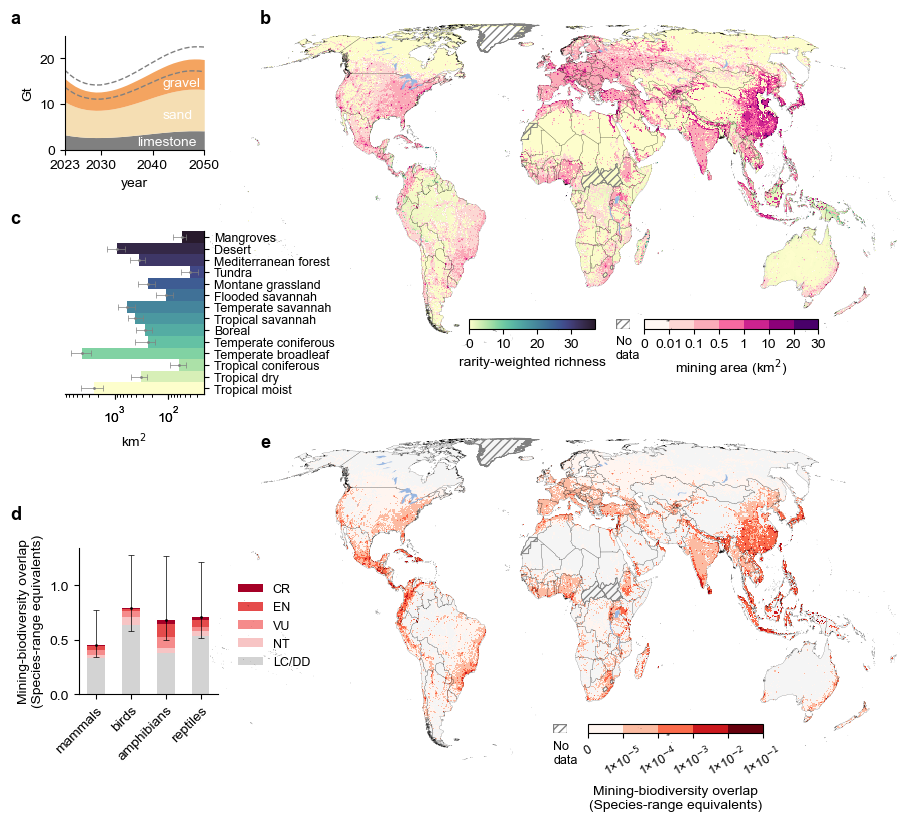

In [46]:
fig = plt.figure(figsize=(10, 8), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

# ===================== panels a/b: RWR + mining area =======================
ax1 = plt.subplot(2, 1, 1, projection=ccrs.EckertIV())
ax1.add_feature(cf.LAKES, zorder=20)
world_map_eck4.plot(color='none', edgecolor='k', lw=0.1, ax=ax1, zorder=10)
im1 = ax1.imshow(np.where(rarity_weighted_richness_50km > 0, rarity_weighted_richness_50km, np.nan), vmin=0, vmax=np.max(rarity_weighted_richness_50km), cmap=cm.deep, interpolation='nearest', origin='upper', extent=display_extent_50km, zorder=1)
im2 = ax1.imshow(np.where(mining_area_2050_BAU_50km, mining_area_2050_BAU_50km, np.nan), cmap='RdPu', interpolation='nearest', norm=norm_MA_50km, origin='upper', extent=display_extent_50km, zorder=5, alpha=1.0)
cax1 = ax1.inset_axes([0.38, 0.05, 0.18, 0.03])
cax2 = ax1.inset_axes([0.63, 0.05, 0.25, 0.03])
cbar1 = fig.colorbar(im1, cax=cax1, orientation='horizontal', label='rarity-weighted richness')
cbar2 = fig.colorbar(im2, cax=cax2, orientation='horizontal', label='mining area (km$^{2}$)')

nodata_area.plot(hatch='////', linewidth=0.5, color='none', edgecolor='grey', zorder=15, ax=ax1)
cax3 = ax1.inset_axes([0.59, 0.05, 0.02, 0.03])
cax3.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='grey', hatch='////'))
cax3.axis('off')
cax3.text(0.0, -3.0, 'No\ndata', fontsize=9)

formatter = FuncFormatter(lambda x, _: f'{x:.2g}')   # 2 significant figures
cbar2.ax.xaxis.set_major_formatter(formatter)
cbar2.formatter = formatter
cbar2.update_ticks()
cbar1.set_ticks([0, 10, 20, 30])
ax1.set_ylim(-7.2e6, 8.6e6)
ax1.axis('off')

ax1_1 = ax1.inset_axes([-.20, 0.60, 0.20, 0.35], zorder=1)
global_extraction_BAU_med.plot.area(stacked=True, color=['grey', 'wheat', 'sandybrown'], lw=0, xlim=(2023, 2050), ylim=(0, 25), ax=ax1_1, ylabel='Gt', legend=False)
global_extraction_BAU_low.sum(axis=1).plot(ls='--', lw=1.0, color='grey', ax=ax1_1)
global_extraction_BAU_upp.sum(axis=1).plot(ls='--', lw=1.0, color='grey', ax=ax1_1)
ax1_1.set_xlim([2023, 2050])
ax1_1.set_xticks([2023, 2030, 2040, 2050])
ax1_1.set_yticks([0, 10, 20])
ax1_1.spines['top'].set_visible(False)
ax1_1.spines['right'].set_visible(False)
ax1_1.text(2037, 1, 'limestone', c='w')
ax1_1.text(2042, 7, 'sand', c='w')
ax1_1.text(2042, 14, 'gravel', c='w', zorder=10)

ax1_2 = ax1.inset_axes([-.20, -0.15, 0.20, 0.50], zorder=1)
ax1_3 = ax1_2.twinx()
ax1_3.barh([i for i in range(14)], MA_abs_by_biome, color=colors, height=1.0)
ax1_3.invert_xaxis()

y = np.arange(len(MA_abs_by_biome))
x = np.array(MA_abs_by_biome)
lower = x - np.array(MA_abs_by_biome_lower)
upper = np.array(MA_abs_by_biome_upper) - x
xerr = np.vstack([lower, upper])
ax1_3.errorbar(x, y, xerr=xerr, fmt='none', ecolor='grey', elinewidth=0.5, capsize=2, capthick=0.5, zorder=10)

ax1_3.set_yticks([i for i in range(0, 14)], biome_labels, rotation=0, fontsize=9)
ax1_3.set_ylim(-0.5, 13.5)
ax1_3.spines['top'].set_visible(False)
ax1_2.spines['top'].set_visible(False)
ax1_3.spines['left'].set_visible(False)
ax1_2.spines['left'].set_visible(False)
ax1_2.set_yticks([])
ax1_3.xaxis.set_visible(True)
ax1_3.set_xlabel('km$^{2}$')
ax1_3.set_xscale('log')
ax1_3.scatter(x, y, color='grey', s=1, zorder=11)

# ===================== panels c/d: mining-biodiversity overlap =============
ax2 = plt.subplot(2, 1, 2, projection=ccrs.EckertIV())
world_map_eck4.plot(color='whitesmoke', edgecolor='none', lw=0.0, ax=ax2, zorder=1)
world_map_eck4.plot(color='none', edgecolor='k', lw=0.1, ax=ax2, zorder=10)
ax2.add_feature(cf.LAKES, zorder=20)

ticks = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
norm_SL_percent = BoundaryNorm(ticks, 256)

im4 = ax2.imshow(np.where(affected_species_range_BAU_50km == 0, np.nan, affected_species_range_BAU_50km), interpolation='nearest', cmap='Reds', norm=norm_SL_percent, origin='upper', extent=display_extent_50km, zorder=5)

cax3 = ax2.inset_axes([0.55, 0.08, 0.25, 0.03])
cbar3 = fig.colorbar(im4, cax=cax3,  orientation='horizontal', label='Mining-biodiversity overlap\n(Species-range equivalents)')

# scientific-notation tick formatter
def sci_fmt(x, pos):
    if x == 0:
        return "0"
    s = f"{x:.0e}"
    base, exp = s.split('e')
    return f"{base}×10$^{{{int(exp)}}}$"

cbar3.ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
for label in cbar3.ax.get_xticklabels():
    label.set_rotation(30)
    label.set_fontsize(9)


ax2.set_ylim(-7.2e6, 8.6e6)
ax2.axis('off')
nodata_area.plot(hatch='////', linewidth=0.5, color='none', edgecolor='grey', zorder=15, ax=ax2)

cax4 = ax2.inset_axes([0.50, 0.08, 0.02, 0.03])
cax4.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='grey', hatch='////'))
cax4.axis('off')
cax4.text(0.0, -3.0, 'No\ndata', fontsize=9)


ax2_1 = ax2.inset_axes([-.18, 0.20, 0.20, 0.45], zorder=1)
ASR_by_taxon_BAU.T.plot.bar(stacked=True, color=['lightgrey', '#f7c4c4', '#f58b8b', '#e54b4b', '#a50026'], ax=ax2_1)

ax2_1.set_xticklabels(['mammals', 'birds', 'amphibians', 'reptiles'], rotation=45, ha='right', rotation_mode='anchor')
handles, labels = ax2_1.get_legend_handles_labels()
ax2_1.legend(handles[::-1], labels[::-1], loc='lower center', bbox_to_anchor=(1.4, 0.1), ncol=1, fontsize=9, frameon=False)
ax2_1.set_yticks([0, 0.5, 1.0, 1.5, 2.0])
ax2_1.set_ylabel('Mining-biodiversity overlap\n(Species-range equivalents)')
ax2_1.spines['top'].set_visible(False)
ax2_1.spines['right'].set_visible(False)
x = np.arange(len(ASR_by_taxon_BAU.sum().values))
y = ASR_by_taxon_BAU.sum().values
lower = y - ASR_by_taxon_BAU_lower.sum().values
upper = ASR_by_taxon_BAU_upper.sum().values - y
yerr = np.vstack([lower, upper])
ax2_1.errorbar(x, y, yerr=yerr, fmt='none', ecolor='k', elinewidth=0.5, capsize=2, capthick=0.5, zorder=10)
ax2_1.scatter(x, y, color='k', s=1, zorder=11)

fig.text(0, 0.99, 'a', fontdict={'size':13, 'weight': 'semibold'})
fig.text(0, 0.74, 'c', fontdict={'size':13, 'weight': 'semibold'})
fig.text(0.25, 0.99, 'b', fontdict={'size':13, 'weight': 'semibold'})
fig.text(0, 0.37, 'd', fontdict={'size':13, 'weight': 'semibold'})
fig.text(0.25, 0.46, 'e', fontdict={'size':13, 'weight': 'semibold'})

plt.show()
fig.savefig(FIG_OUT, dpi=600, bbox_inches='tight')

In [47]:
b_1 = (global_sand_extraction_BAU_med.loc[2050] / 1e6).round(1).values[0]
b_2 = (global_sand_extraction_BAU_low.loc[2050] / 1e6).round(1).values[0]
b_3 = (global_sand_extraction_BAU_upp.loc[2050] / 1e6).round(1).values[0]
b_4 = (global_gravel_extraction_BAU_med.loc[2050] / 1e6).round(1).values[0]
b_5 = (global_gravel_extraction_BAU_low.loc[2050] / 1e6).round(1).values[0]
b_6 = (global_gravel_extraction_BAU_upp.loc[2050] / 1e6).round(1).values[0]
b_7 = (global_limestone_extraction_BAU_med.loc[2050] / 1e6).round(1).values[0]
b_8 = (global_limestone_extraction_BAU_low.loc[2050] / 1e6).round(1).values[0]
b_9 = (global_limestone_extraction_BAU_upp.loc[2050] / 1e6).round(1).values[0]

print(f'As a result, global demand for sand, gravel, and limestone embodied in concrete and mortar \n\
is projected rise to {b_1:.1f} Gt yr-1 (95% CI: {b_2:.1f}-{b_3:.1f} Gt yr-1), \n\
{b_4:.1f} Gt yr-1 (95% CI: {b_5:.1f}-{b_6:.1f} Gt yr-1), \n\
and {b_7:.1f} Gt yr-1 (95% CI: {b_8:.1f}-{b_9:.1f} Gt yr-1) by 2050, respectively (Figure 1a).')

As a result, global demand for sand, gravel, and limestone embodied in concrete and mortar 
is projected rise to 9.0 Gt yr-1 (95% CI: 8.2-9.9 Gt yr-1), 
6.6 Gt yr-1 (95% CI: 5.8-7.4 Gt yr-1), 
and 4.1 Gt yr-1 (95% CI: 3.0-5.2 Gt yr-1) by 2050, respectively (Figure 1a).


In [48]:
d_1 = ((global_sand_extraction_BAU_med.sum() + global_gravel_extraction_BAU_med.sum() + global_limestone_extraction_BAU_med.sum()) / 1e6).values[0]
d_2 = ((global_sand_extraction_BAU_low.sum() + global_gravel_extraction_BAU_low.sum() + global_limestone_extraction_BAU_low.sum()) / 1e6).values[0]
d_3 = ((global_sand_extraction_BAU_upp.sum() + global_gravel_extraction_BAU_upp.sum() + global_limestone_extraction_BAU_upp.sum()) / 1e6).values[0]
d_4 = np.nansum(mining_area_2050_BAU_50km)
d_5 = np.nansum(mining_area_2050_BAU_50km_lower)
d_6 = np.nansum(mining_area_2050_BAU_50km_upper)

print(f'Under the BAU scenario, cumulative global extraction of {d_1:.0f} Gt (95% CI: {d_2:.0f}-{d_3:.0f} Gt) \n\
between 2023 and 2050 is projected to disturb at least an additional {d_4:,.0f} km2 (95% CI: {d_5:,.0f}-{d_6:,.0f}) km2')

order = np.argsort(MA_abs_by_biome)[::-1]
biome_parts = ', '.join(f'{biome_labels[i]} ({MA_abs_by_biome[i]:,.0f} km2, {MA_prop_by_biome[i]:.0f}%)' for i in order[:4])
print(f'The largest projected expansion occurs in {biome_parts}.')

Under the BAU scenario, cumulative global extraction of 446 Gt (95% CI: 390-503 Gt) 
between 2023 and 2050 is projected to disturb at least an additional 10,143 km2 (95% CI: 7,077-16,306) km2
The largest projected expansion occurs in Temperate broadleaf (4,079 km2, 40%), Tropical moist (2,399 km2, 24%), Desert (892 km2, 9%), Temperate savannah (582 km2, 6%).


In [49]:
b_1 = ASR_by_taxon_BAU.sum().sum()
b_2 = ASR_by_taxon_BAU_lower.sum().sum()
b_3 = ASR_by_taxon_BAU_upper.sum().sum()
b_4 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['mammals'] * 100
b_5 = ASR_by_taxon_BAU.sum()['mammals']
b_6 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['birds'] * 100
b_7 = ASR_by_taxon_BAU.sum()['birds']
b_8 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['amphibians'] * 100
b_9 = ASR_by_taxon_BAU.sum()['amphibians']
b_10 = (ASR_by_taxon_BAU.sum() / ASR_by_taxon_BAU.sum().sum())['reptiles'] * 100
b_11 = ASR_by_taxon_BAU.sum()['reptiles']

print(f'Globally, projected mining area expansion overlaps a total of {b_1:.1f} (95% CI: {b_2:.1f}-{b_3:.1f}) species-range equivalents. \n\
Of this total, mammals account for {b_4:.0f}% ({b_5:.1f} species-range equivalent), \n\
birds {b_6:.0f}% ({b_7:.1f} species-range equivalent), amphibians {b_8:.0f}% ({b_9:.1f} species-range equivalents), \n\
and reptiles {b_10:.0f}% ({b_11:.1f} species-range equivalent)')

Globally, projected mining area expansion overlaps a total of 2.6 (95% CI: 1.9-4.5) species-range equivalents. 
Of this total, mammals account for 17% (0.5 species-range equivalent), 
birds 30% (0.8 species-range equivalent), amphibians 26% (0.7 species-range equivalents), 
and reptiles 27% (0.7 species-range equivalent)


In [50]:
c_1 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['CR'] * 100
c_2 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['EN'] * 100
c_3 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['VU'] * 100
c_4 = (ASR_by_taxon_BAU.sum(axis=1) / ASR_by_taxon_BAU.sum().sum())['NT'] * 100

print(f'Impacts span all IUCN Red List categories, \n\
with critically endangered species contributing {c_1:.0f}% of the total overlap, \n\
endangered species {c_2:.0f}%, vulnerable species {c_3:.0f}%, and near-threatened species {c_4:.0f}%')

Impacts span all IUCN Red List categories, 
with critically endangered species contributing 3% of the total overlap, 
endangered species 9%, vulnerable species 9%, and near-threatened species 7%
